# AlertaChuva · IA & Machine Learning
**Global Solution 2026.2 · CitizenTech · Jardim Pantanal (São Miguel Paulista), São Paulo**

Integrantes: Danilo Affonso Luz Rios (RM 554791) · Lucca Natario do Vale (RM 95688) · Thiago Feltrin Geraldes (RM 555805)

**Pergunta de ML:** *com os dados meteorológicos observados hoje pelo INMET, qual a probabilidade de amanhã cair **20 mm ou mais** de chuva em São Paulo?*

- **Tipo de problema:** classificação binária (dia seguinte com chuva muito intensa = 1).
- **Por que 20 mm/dia:** é o índice **R20mm** ("dia de chuva muito intensa") da OMM/ETCCDI, padrão internacional para extremos de precipitação. Analisamos também os dias **≥ 50 mm**, faixa do aviso **laranja (perigo)** do INMET.
- **Para o cidadão:** a probabilidade vira o nível de risco (baixo / atenção / alto) que o app mostra no fim do dia, com cerca de 12 a 24 horas de antecedência.
- **Dados:** INMET, estação automática **A701 – São Paulo/Mirante de Santana**, série diária de **24/07/2006 a 25/04/2025** (reais e públicos, sem dados simulados).

## 1. Ambiente e leitura dos dados reais

In [ ]:
import json, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_score, recall_score, f1_score, fbeta_score,
                             confusion_matrix, precision_recall_curve, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import sklearn, xgboost
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
SEED = 42
RAW = Path('dados/raw'); FIG = Path('figuras'); OUT = Path('resultados')
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
print('pandas', pd.__version__, '| scikit-learn', sklearn.__version__, '| xgboost', xgboost.__version__)

In [2]:
def ler_bdmep(arquivo):
    meta = dict(l.strip().split(': ', 1) for l in open(arquivo, encoding='utf-8').readlines()[:9])
    df = pd.read_csv(arquivo, sep=';', skiprows=10, na_values='null')
    df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
    df['data'] = pd.to_datetime(df.pop('Data Medicao'))
    return meta, df.set_index('data')

ARQ = RAW / 'dados_A701_D_2006-07-24_2025-04-25.csv'
meta, bruto = ler_bdmep(ARQ)
print(json.dumps(meta, ensure_ascii=False, indent=1))
print('SHA-256:', hashlib.sha256(ARQ.read_bytes()).hexdigest())
bruto.columns = ['chuva', 'temp', 'umid', 'vento']
print(bruto.shape); bruto.describe().round(2)

{
 "Nome": "SAO PAULO - MIRANTE",
 "Codigo Estacao": "A701",
 "Latitude": "-23.4962888",
 "Longitude": "-46.6200666",
 "Altitude": "785.64",
 "Situacao": "Operante",
 "Data Inicial": "2006-07-24",
 "Data Final": "2025-04-25",
 "Periodicidade da Medicao": "Diaria"
}
SHA-256: 0663a8bc4ef0e9a7d0e80b12728ff23874e0cd222db9a64f15fdf095d7915463
(6851, 4)


,chuva,temp,umid,vento
count,6770.00,6781.00,6819.00,6789.0
mean,4.45,20.50,69.99,1.9
std,11.10,3.36,10.93,0.7
min,0.00,8.00,23.30,0.0
25%,0.00,18.30,64.10,1.5
50%,0.00,20.80,71.10,1.9
75%,2.40,23.00,77.40,2.3
max,125.60,31.00,98.90,5.6


### 1.1 Verificação de integridade
O arquivo foi conferido contra **dois outros exports independentes do mesmo BDMEP**: um diário (2020–2024, com outras variáveis) e um mensal (2006–2020). Se os números batem, o dado é o oficial do INMET e não foi alterado.

In [3]:
_, outro_diario = ler_bdmep(RAW / 'dados_A701_D_2020-01-01_2024-11-20.csv')
_, mensal = ler_bdmep(RAW / 'dados_A701_M_2006-07-24_2020-12-31.csv')
j = pd.concat([bruto.chuva, outro_diario.iloc[:, 0]], axis=1, keys=['a', 'b']).dropna()
m = pd.concat([bruto.chuva.resample('ME').sum(min_count=20), mensal.iloc[:, 1]], axis=1, keys=['a', 'm']).dropna()
integridade = {
    'dias_comparados': len(j), 'dias_identicos_%': float(round(100 * (abs(j.a - j.b) < 0.05).mean(), 2)),
    'meses_comparados': len(m), 'meses_identicos_%': float(round(100 * (abs(m.a - m.m) < 1).mean(), 2))}
integridade

{'dias_comparados': 1743,
 'dias_identicos_%': 99.94,
 'meses_comparados': 169,
 'meses_identicos_%': 100.0}

## 2. Limpeza e análise exploratória

In [4]:
print('Faltantes por variável (%):'); print((bruto.isna().mean() * 100).round(2))
df = bruto.asfreq('D')
print('Dias no calendário:', len(df), '| dias sem nenhuma medição:', df.isna().all(axis=1).sum())
assert (df.chuva.dropna() >= 0).all() and df.umid.dropna().between(0, 100).all()
assert df.temp.dropna().between(0, 40).all()
print('Maior chuva diária registrada: %.1f mm em %s' % (df.chuva.max(), df.chuva.idxmax().date()))

Faltantes por variável (%):
chuva    1.18
temp     1.02
umid     0.47
vento    0.90
dtype: float64
Dias no calendário: 6851 | dias sem nenhuma medição: 29
Maior chuva diária registrada: 125.6 mm em 2025-01-25


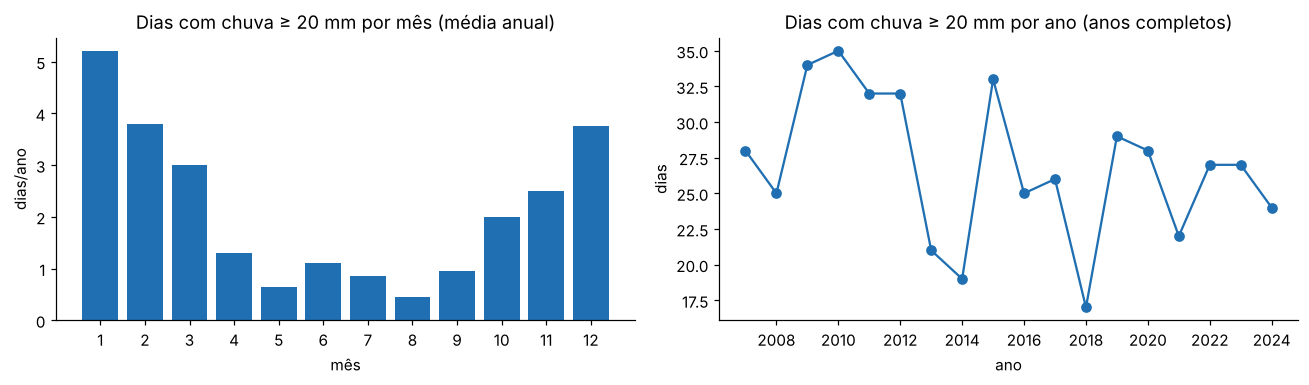

In [5]:
LIMIAR = 20.0
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
por_mes = df.chuva.ge(LIMIAR).groupby(df.index.month).sum() / df.index.year.nunique()
ax[0].bar(por_mes.index, por_mes.values, color='#1f6fb2')
ax[0].set(title='Dias com chuva ≥ 20 mm por mês (média anual)', xlabel='mês', ylabel='dias/ano', xticks=range(1, 13))
anual = df.chuva.ge(LIMIAR).groupby(df.index.year).sum()
ax[1].plot(anual.index[1:-1], anual.values[1:-1], marker='o', color='#1f6fb2')
ax[1].set(title='Dias com chuva ≥ 20 mm por ano (anos completos)', xlabel='ano', ylabel='dias')
ax[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout(); plt.savefig(FIG / '01_sazonalidade.png', bbox_inches='tight'); plt.show()

A chuva muito intensa é **fortemente sazonal** (dezembro a março concentram a maioria dos eventos). Por isso o modelo recebe o dia do ano como variável cíclica.

## 3. Engenharia de variáveis e alvo
Tudo o que entra no modelo é conhecido **no fim do dia D**; o alvo é a chuva do dia **D+1**. Nenhuma variável usa informação do futuro (sem vazamento).

In [6]:
X = pd.DataFrame(index=df.index)
X['chuva_hoje'] = df.chuva
for n in (3, 7, 15, 30):
    X[f'chuva_{n}d'] = df.chuva.rolling(n, min_periods=n - 1).sum()
seco = df.chuva.lt(1).astype(int)
X['dias_sem_chuva'] = seco.groupby((seco == 0).cumsum()).cumsum()
X['temp'] = df.temp
X['temp_var_1d'] = df.temp.diff()
X['temp_anom_30d'] = df.temp - df.temp.rolling(30, min_periods=20).mean()
X['umid'] = df.umid
X['umid_var_1d'] = df.umid.diff()
X['umid_3d'] = df.umid.rolling(3, min_periods=2).mean()
X['vento'] = df.vento
X['vento_var_1d'] = df.vento.diff()
doy = df.index.dayofyear
X['sazon_sin'] = np.sin(2 * np.pi * doy / 365.25); X['sazon_cos'] = np.cos(2 * np.pi * doy / 365.25)

chuva_amanha = df.chuva.shift(-1)
dados = X.assign(chuva_amanha=chuva_amanha).dropna()
dados['alvo'] = (dados.chuva_amanha >= LIMIAR).astype(int)
FEATS = list(X.columns)
print('Linhas úteis:', len(dados), 'de', len(df), '| variáveis:', len(FEATS))
print('Prevalência do alvo: %.2f%%' % (100 * dados.alvo.mean()))

Linhas úteis: 6359 de 6851 | variáveis: 16
Prevalência do alvo: 7.58%


## 4. Divisão treino/teste (temporal)
Como é série temporal, a divisão é **cronológica**: treino = 2006–2021, teste = 2022–abr/2025. Embaralhar os dias deixaria o modelo "ver o futuro" e inflaria as métricas.

In [7]:
CORTE = '2021-12-31'
treino, teste = dados.loc[:CORTE], dados.loc['2022-01-01':]
Xtr, ytr, Xte, yte = treino[FEATS], treino.alvo, teste[FEATS], teste.alvo
resumo_split = pd.DataFrame({
    'período': [f'{treino.index.min().date()} a {treino.index.max().date()}', f'{teste.index.min().date()} a {teste.index.max().date()}'],
    'dias': [len(treino), len(teste)], 'eventos ≥20mm': [int(ytr.sum()), int(yte.sum())],
    'prevalência %': [round(100 * ytr.mean(), 2), round(100 * yte.mean(), 2)]}, index=['treino', 'teste'])
resumo_split

,período,dias,eventos ≥20mm,prevalência %
treino,2006-08-24 a 2021-12-31,5333,401,7.52
teste,2022-01-01 a 2025-04-24,1026,81,7.89


## 5. Modelo escolhido: XGBoost
**Por que XGBoost (e não os outros da lista):**
- Dados **tabulares** com relações não lineares e interações (ex.: calor acima do normal *e* umidade subindo no verão): árvores com boosting capturam isso sem normalização.
- Lida bem com **classe rara** (7% de dias positivos) via `scale_pos_weight`.
- **LSTM** exigiria muito mais dados para pouca série (≈6,5 mil dias); **KMeans** é não supervisionado e não responde à pergunta; **Random Forest** seria aceitável, mas o boosting costuma ser melhor em eventos raros e expõe a taxa de aprendizado como controle de overfitting.

**Referências de comparação (baselines):** (a) *persistência*: "se choveu ≥ 20 mm hoje, alerta amanhã"; (b) *climatologia*: frequência histórica do mês.

## 6. Treino com diferentes hiperparâmetros (36 combinações × validação cruzada temporal)
- **3 hiperparâmetros:** `max_depth` (complexidade da árvore), `learning_rate` (tamanho do passo) e `n_estimators` (nº de árvores) → 4 × 3 × 3 = **36 combinações** (o mínimo exigido é 10).
- **Validação cruzada só no treino**, com `TimeSeriesSplit` (5 dobras, cada validação é posterior ao seu treino). O teste fica intocado até o fim.
- **Métrica de seleção:** *Average Precision* (área sob a curva Precisão-Recall), adequada para classe rara. Acurácia seria enganosa: dizer "nunca chove forte" acertaria 93%.

In [8]:
spw = float((ytr == 0).sum() / (ytr == 1).sum())
base = XGBClassifier(objective='binary:logistic', eval_metric='logloss', subsample=0.8, colsample_bytree=0.8,
                     min_child_weight=5, scale_pos_weight=spw, random_state=SEED, n_jobs=4, tree_method='hist')
grade = {'max_depth': [1, 2, 3, 5], 'learning_rate': [0.01, 0.03, 0.1], 'n_estimators': [100, 300, 600]}
tscv = TimeSeriesSplit(n_splits=5)
busca = GridSearchCV(base, grade, cv=tscv, scoring={'AP': 'average_precision', 'ROC_AUC': 'roc_auc'},
                     refit='AP', return_train_score=True, n_jobs=1)
busca.fit(Xtr, ytr)
r = pd.DataFrame(busca.cv_results_)
tab = pd.DataFrame({
    'max_depth': r.param_max_depth, 'learning_rate': r.param_learning_rate, 'n_estimators': r.param_n_estimators,
    'AP_treino': r.mean_train_AP.round(3), 'AP_validação': r.mean_test_AP.round(3), 'AP_val_desvio': r.std_test_AP.round(3),
    'ROC_validação': r.mean_test_ROC_AUC.round(3)})
tab['gap_overfit'] = (tab.AP_treino - tab.AP_validação).round(3)
tab = tab.sort_values('AP_validação', ascending=False).reset_index(drop=True); tab.index += 1
tab.to_csv(OUT / 'grid_search.csv', index_label='rank')
print('scale_pos_weight =', round(spw, 2), '| melhor combinação:', busca.best_params_)
tab

scale_pos_weight = 12.3 | melhor combinação: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 300}


,max_depth,learning_rate,n_estimators,AP_treino,AP_validação,AP_val_desvio,ROC_validação,gap_overfit
1,3,0.01,300,0.507,0.322,0.058,0.822,0.185
2,2,0.01,300,0.410,0.321,0.052,0.819,0.089
3,2,0.03,100,0.399,0.319,0.053,0.818,0.080
4,2,0.01,600,0.473,0.315,0.062,0.822,0.158
5,1,0.03,300,0.382,0.315,0.053,0.816,0.067
6,1,0.10,100,0.382,0.315,0.054,0.818,0.067
7,2,0.10,100,0.521,0.314,0.055,0.817,0.207
8,1,0.03,600,0.423,0.314,0.058,0.817,0.109
9,3,0.03,100,0.493,0.313,0.056,0.818,0.180
10,3,0.01,600,0.599,0.312,0.062,0.820,0.287


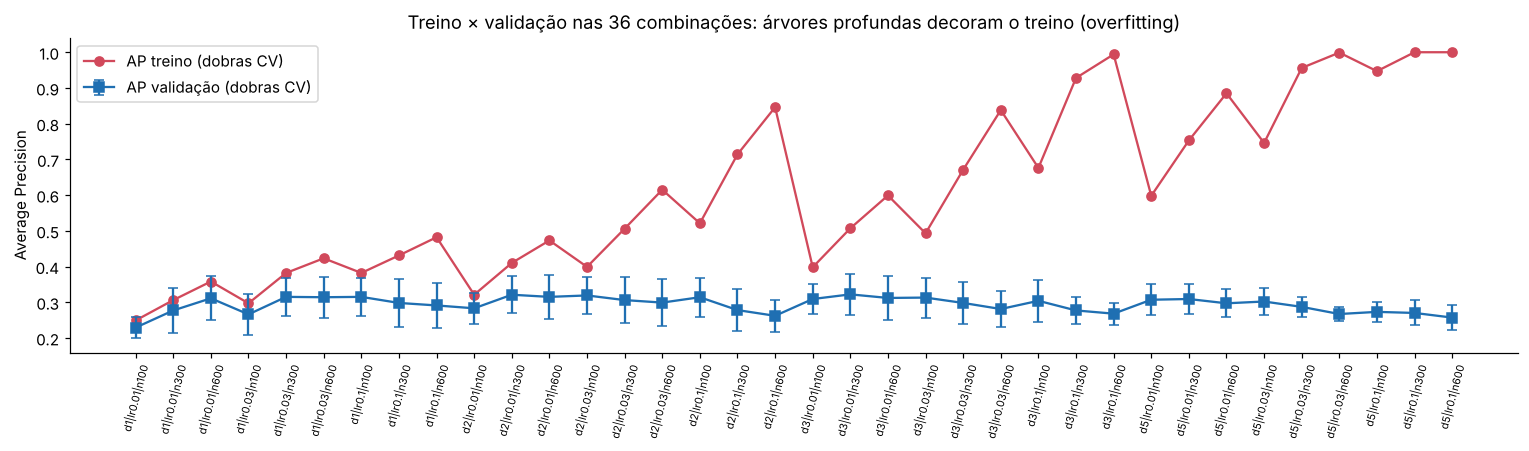

In [9]:
fig, ax = plt.subplots(figsize=(14, 4.2))
o = tab.sort_values(['max_depth', 'learning_rate', 'n_estimators'])
lbl = [f'd{a}|lr{b}|n{c}' for a, b, c in zip(o.max_depth, o.learning_rate, o.n_estimators)]
xs = np.arange(len(o))
ax.plot(xs, o.AP_treino, 'o-', label='AP treino (dobras CV)', color='#d1495b')
ax.errorbar(xs, o.AP_validação, yerr=o.AP_val_desvio, fmt='s-', capsize=3, label='AP validação (dobras CV)', color='#1f6fb2')
ax.set_xticks(xs, lbl, rotation=75, fontsize=7); ax.set_ylabel('Average Precision'); ax.legend()
ax.set_title('Treino × validação nas 36 combinações: árvores profundas decoram o treino (overfitting)')
plt.tight_layout(); plt.savefig(FIG / '02_grid_treino_vs_validacao.png', bbox_inches='tight'); plt.show()

**Leitura do gráfico:** quanto maior `max_depth` e `n_estimators`, mais o AP de treino sobe em direção a 1,0 enquanto o de validação estagna ou cai. Essa distância é o **overfitting**: o modelo passa a decorar dias específicos do passado. A combinação escolhida é a de melhor AP na validação, não no treino.

## 7. Escolha do limiar de alerta (só com dados de treino)
O modelo devolve uma probabilidade; o app precisa de um **"alerta sim/não"**. O limiar foi escolhido nas previsões *fora da dobra* do treino maximizando o **F2**, que pesa o recall 2× mais que a precisão: **deixar de avisar um morador custa mais que um alarme falso**.

In [10]:
melhor = busca.best_estimator_
oof_p, oof_y = [], []
for itr, iva in tscv.split(Xtr):
    m_ = XGBClassifier(**melhor.get_params()).fit(Xtr.iloc[itr], ytr.iloc[itr])
    oof_p.append(m_.predict_proba(Xtr.iloc[iva])[:, 1]); oof_y.append(ytr.iloc[iva].values)
oof_p, oof_y = np.concatenate(oof_p), np.concatenate(oof_y)
cands = np.round(np.arange(0.05, 0.96, 0.01), 2)
f2 = [fbeta_score(oof_y, oof_p >= t, beta=2) for t in cands]
LIM_ALTO = float(cands[int(np.argmax(f2))])
LIM_ATENCAO = round(LIM_ALTO / 2, 2)
print(f'Limiar ALTO = {LIM_ALTO} (F2 OOF = {max(f2):.3f}) | limiar ATENÇÃO = {LIM_ATENCAO}')

Limiar ALTO = 0.49 (F2 OOF = 0.475) | limiar ATENÇÃO = 0.24


## 8. Resultados: treino × teste lado a lado

In [11]:
def metricas(y, p, lim):
    yhat = (p >= lim).astype(int)
    return {'Average Precision (PR-AUC)': average_precision_score(y, p), 'ROC-AUC': roc_auc_score(y, p),
            'Brier (menor = melhor)': brier_score_loss(y, p), 'Precisão': precision_score(y, yhat, zero_division=0),
            'Recall (eventos avisados)': recall_score(y, yhat), 'F1': f1_score(y, yhat), 'F2': fbeta_score(y, yhat, beta=2)}

p_tr, p_te = melhor.predict_proba(Xtr)[:, 1], melhor.predict_proba(Xte)[:, 1]
res = pd.DataFrame({'Treino (2006–2021)': metricas(ytr, p_tr, LIM_ALTO), 'Teste (2022–2025)': metricas(yte, p_te, LIM_ALTO)})
res['diferença'] = res.iloc[:, 0] - res.iloc[:, 1]

clim = treino.groupby(treino.index.month).alvo.mean()
p_clim = teste.index.month.map(clim).values
pers = (teste.chuva_hoje >= LIMIAR).astype(int).values
base_tab = pd.DataFrame({
    'XGBoost': [average_precision_score(yte, p_te), roc_auc_score(yte, p_te), recall_score(yte, p_te >= LIM_ALTO), precision_score(yte, p_te >= LIM_ALTO)],
    'Climatologia do mês': [average_precision_score(yte, p_clim), roc_auc_score(yte, p_clim), np.nan, np.nan],
    'Persistência (choveu ≥20 hoje)': [average_precision_score(yte, pers), roc_auc_score(yte, pers), recall_score(yte, pers), precision_score(yte, pers)],
    'Sorteio (prevalência)': [yte.mean(), 0.5, np.nan, np.nan]},
    index=['AP (teste)', 'ROC-AUC (teste)', 'Recall (teste)', 'Precisão (teste)']).round(3)
display(res.round(3)); display(base_tab)

,Treino (2006–2021),Teste (2022–2025),diferença
Average Precision (PR-AUC),0.406,0.270,0.136
ROC-AUC,0.891,0.820,0.072
Brier (menor = melhor),0.147,0.176,-0.029
Precisão,0.233,0.196,0.038
Recall (eventos avisados),0.873,0.778,0.095
F1,0.368,0.313,0.056
F2,0.564,0.488,0.076


,XGBoost,Climatologia do mês,Persistência (choveu ≥20 hoje),Sorteio (prevalência)
AP (teste),0.270,0.133,0.105,0.079
ROC-AUC (teste),0.820,0.676,0.570,0.500
Recall (teste),0.778,NaN,0.210,NaN
Precisão (teste),0.196,NaN,0.205,NaN


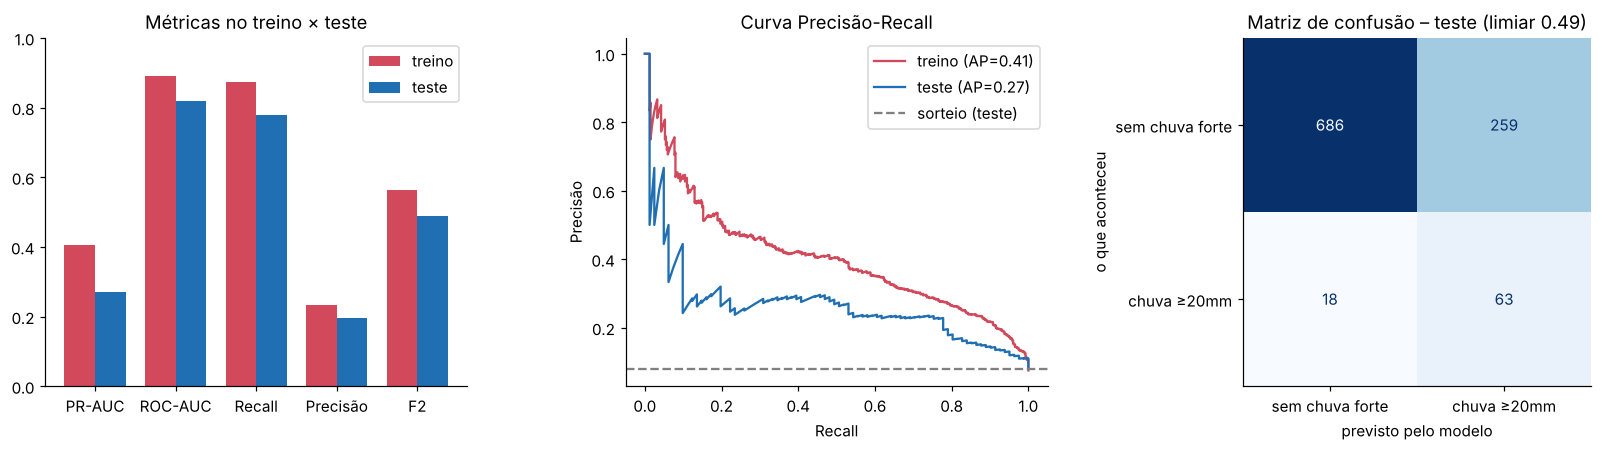

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
k = ['Average Precision (PR-AUC)', 'ROC-AUC', 'Recall (eventos avisados)', 'Precisão', 'F2']
xx = np.arange(len(k)); w = 0.38
ax[0].bar(xx - w/2, res.loc[k].iloc[:, 0], w, label='treino', color='#d1495b')
ax[0].bar(xx + w/2, res.loc[k].iloc[:, 1], w, label='teste', color='#1f6fb2')
ax[0].set_xticks(xx, ['PR-AUC', 'ROC-AUC', 'Recall', 'Precisão', 'F2']); ax[0].set_ylim(0, 1); ax[0].legend()
ax[0].set_title('Métricas no treino × teste')
for nome, y, p, c in [('treino', ytr, p_tr, '#d1495b'), ('teste', yte, p_te, '#1f6fb2')]:
    pr, rc, _ = precision_recall_curve(y, p); ax[1].plot(rc, pr, label=f'{nome} (AP={average_precision_score(y, p):.2f})', color=c)
ax[1].axhline(yte.mean(), ls='--', color='gray', label='sorteio (teste)')
ax[1].set(xlabel='Recall', ylabel='Precisão', title='Curva Precisão-Recall'); ax[1].legend()
ConfusionMatrixDisplay(confusion_matrix(yte, p_te >= LIM_ALTO), display_labels=['sem chuva forte', 'chuva ≥20mm']).plot(ax=ax[2], colorbar=False, cmap='Blues')
ax[2].set(title=f'Matriz de confusão – teste (limiar {LIM_ALTO})', xlabel='previsto pelo modelo', ylabel='o que aconteceu')
plt.tight_layout(); plt.savefig(FIG / '03_treino_vs_teste.png', bbox_inches='tight'); plt.show()

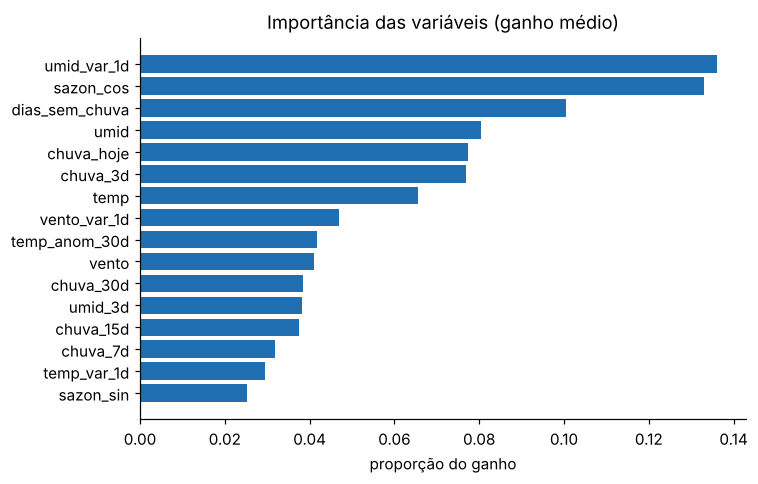

In [13]:
imp = pd.Series(melhor.get_booster().get_score(importance_type='gain')).reindex(FEATS).fillna(0).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.5)); ax.barh(imp.index, imp.values / imp.sum(), color='#1f6fb2')
ax.set_title('Importância das variáveis (ganho médio)'); ax.set_xlabel('proporção do ganho')
plt.tight_layout(); plt.savefig(FIG / '04_importancia.png', bbox_inches='tight'); plt.show()

## 9. O que o resultado significa para o cidadão
A saída do modelo vira o nível exibido no app. Como o treino usou `scale_pos_weight` para dar peso à classe rara, o número de 0 a 1 funciona como **índice de risco**, e não como probabilidade literal (por isso o Brier é alto). Para o cidadão, o que vale é a tabela abaixo: o que **realmente aconteceu** no teste (dados nunca vistos) em cada nível, e quantos dias extremos (≥ 50 mm, aviso laranja do INMET) foram avisados na véspera.

In [14]:
nivel = pd.cut(p_te, [-0.01, LIM_ATENCAO, LIM_ALTO, 1.01], labels=['BAIXO', 'ATENÇÃO', 'ALTO'], right=False)
leitura = pd.DataFrame({'nivel': nivel, 'evento': yte.values, 'chuva': teste.chuva_amanha.values}).groupby('nivel', observed=False).agg(
    dias=('evento', 'size'), dias_com_chuva_forte=('evento', 'sum'), chuva_media_mm=('chuva', 'mean'))
leitura['% dos dias com ≥20mm'] = (100 * leitura.dias_com_chuva_forte / leitura.dias).round(1)
leitura['% de todos os eventos'] = (100 * leitura.dias_com_chuva_forte / yte.sum()).round(1)
display(leitura.round(1))

ext = teste.chuva_amanha >= 50
ext_tab = pd.DataFrame({'data do evento': (teste.index[ext] + pd.Timedelta(days=1)).date, 'chuva (mm)': teste.chuva_amanha[ext].values,
                        'índice de risco na véspera': p_te[ext].round(2), 'nível exibido': nivel[ext.values]})
display(ext_tab)
avisados_ext = int((p_te[ext] >= LIM_ATENCAO).sum())
print(f'Dias extremos (≥50 mm) no teste: {ext.sum()} | com nível ATENÇÃO ou ALTO na véspera: {avisados_ext}')

,dias,dias_com_chuva_forte,chuva_media_mm,% dos dias com ≥20mm,% de todos os eventos
nivel,,,,,
BAIXO,373,3,0.8,0.8,3.7
ATENÇÃO,331,15,3.1,4.5,18.5
ALTO,322,63,11.6,19.6,77.8


,data do evento,chuva (mm),índice de risco na véspera,nível exibido
0,2022-01-30,66.4,0.72,ALTO
1,2022-03-16,52.8,0.81,ALTO
2,2023-02-19,50.6,0.86,ALTO
3,2023-02-21,60.4,0.63,ALTO
4,2023-03-11,58.4,0.80,ALTO
5,2023-04-19,52.2,0.60,ALTO
6,2023-11-16,51.2,0.35,ATENÇÃO
7,2024-01-11,54.4,0.46,ATENÇÃO
8,2024-01-13,69.0,0.80,ALTO
9,2024-02-14,71.4,0.20,BAIXO


Dias extremos (≥50 mm) no teste: 16 | com nível ATENÇÃO ou ALTO na véspera: 14


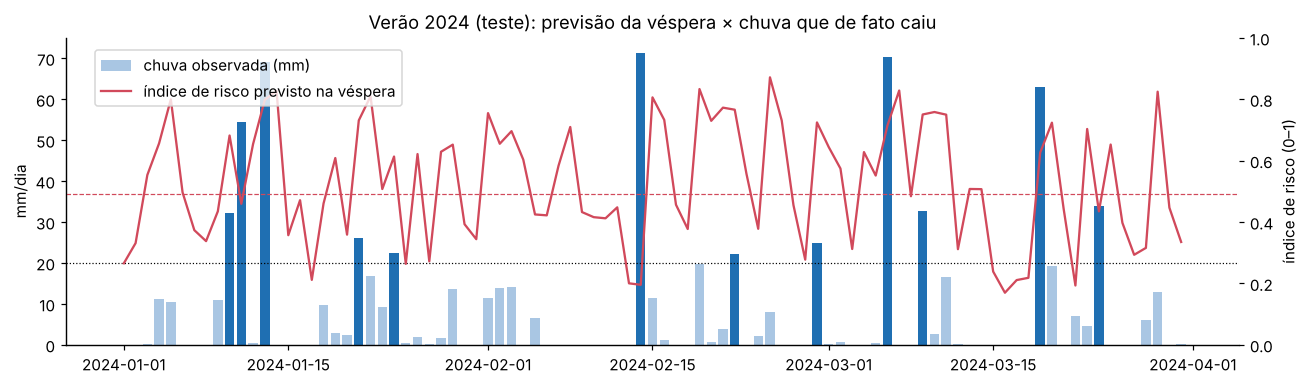

In [15]:
fig, ax = plt.subplots(figsize=(12, 3.6))
jan = slice('2024-01-01', '2024-03-31')
s = pd.Series(p_te, index=teste.index + pd.Timedelta(days=1)).loc[jan]
ch = teste.chuva_amanha.copy(); ch.index = ch.index + pd.Timedelta(days=1); ch = ch.loc[jan]
ax.bar(ch.index, ch.values, color=np.where(ch.values >= LIMIAR, '#1f6fb2', '#a9c6e3'), label='chuva observada (mm)')
ax2 = ax.twinx(); ax2.plot(s.index, s.values, color='#d1495b', label='índice de risco previsto na véspera')
ax2.axhline(LIM_ALTO, ls='--', color='#d1495b', lw=.8); ax2.set_ylim(0, 1); ax2.set_ylabel('índice de risco (0–1)')
ax.axhline(LIMIAR, ls=':', color='k', lw=.8); ax.set_ylabel('mm/dia')
ax.set_title('Verão 2024 (teste): previsão da véspera × chuva que de fato caiu')
fig.legend(loc='upper left', bbox_to_anchor=(0.07, 0.88)); plt.tight_layout()
plt.savefig(FIG / '05_verao_2024.png', bbox_inches='tight'); plt.show()

## 10. Artefatos para a API do AlertaChuva

In [16]:
Path('modelo').mkdir(exist_ok=True)
melhor.save_model('modelo/xgb_alertachuva.json')
cfg = {'features': FEATS, 'limiar_alto': LIM_ALTO, 'limiar_atencao': LIM_ATENCAO, 'alvo': 'chuva D+1 >= 20 mm',
       'estacao': 'INMET A701', 'treino_ate': CORTE, 'melhores_parametros': busca.best_params_}
json.dump(cfg, open('modelo/config.json', 'w'), ensure_ascii=False, indent=2)
resumo = {'integridade': integridade, 'split': resumo_split.reset_index().to_dict('records'), 'melhores_parametros': busca.best_params_,
          'metricas': res.round(4).to_dict(), 'baselines': base_tab.to_dict(), 'leitura_cidadao': leitura.reset_index().astype({'nivel': str}).to_dict('records'),
          'extremos_50mm': {'total': int(ext.sum()), 'avisados': avisados_ext}, 'limiares': {'alto': LIM_ALTO, 'atencao': LIM_ATENCAO}}
json.dump(resumo, open(OUT / 'resumo.json', 'w'), ensure_ascii=False, indent=2, default=str)
print(json.dumps(cfg, ensure_ascii=False, indent=1))

{
 "features": [
  "chuva_hoje",
  "chuva_3d",
  "chuva_7d",
  "chuva_15d",
  "chuva_30d",
  "dias_sem_chuva",
  "temp",
  "temp_var_1d",
  "temp_anom_30d",
  "umid",
  "umid_var_1d",
  "umid_3d",
  "vento",
  "vento_var_1d",
  "sazon_sin",
  "sazon_cos"
 ],
 "limiar_alto": 0.49,
 "limiar_atencao": 0.24,
 "alvo": "chuva D+1 >= 20 mm",
 "estacao": "INMET A701",
 "treino_ate": "2021-12-31",
 "melhores_parametros": {
  "learning_rate": 0.01,
  "max_depth": 3,
  "n_estimators": 300
 }
}


## 11. Conclusão
Os números estão comentados no `RELATORIO_ML.md`. Em resumo: o modelo identifica com antecedência de um dia **a maior parte dos dias de chuva muito intensa**, com desempenho bem acima da climatologia e da regra de persistência. O custo são alarmes falsos, aceitáveis para quem mora em área de risco. A limitação principal é usar **uma única estação e variáveis diárias**, o que não captura tempestades convectivas isoladas. O próximo passo natural é incluir dados horários, pressão atmosférica e o sensor de nível de água (ESP32) do próprio bairro.